# Q1D | Train Linear Regression

> Train a Linear Regression model using the training data with four-fold cross-validation and with appropriate evaluation metric. Do this with a closed-form solution (using the Normal Equation or SVD) and with SGD. Then focus on SGD and perform Ridge, Lasso and Elastic Net regularization – try three values of penalty term and describe its impact. Explore the impact of other hyperparameters of your choice, such as learning rate (no need for grid search). Describe your findings. Select the best-performing regularization set of hyperparameters and train that model on the entire training dataset. For SGD, display the training and validation loss as a function of training epochs for the selected model. (Hint: In scikit-learn, max_iter counts epochs (full passes over the training set). To plot training/validation loss by epoch with SGDRegressor, set max_iter=1 and warm_start=True, then call fit(...) in a loop; after each call (each epoch), compute and record Train and Validation RMSE). Ensure reproducibility by using a seed.

**IMPORTANT**

This notebook uses only the train dataset, so no modeling decision is influenced by the test data (data snooping). Every score below is a cross validation score on the training rows.

# Answer Summary

**Cross validation and metric**
- Four-fold cross validation (`KFold`, shuffled with seed 42), scored by RMSE in `Life Ladder` points. Validation rows are complete rows only, like the test file.
- Each choice starts from the simpler option, which another replaces only if its mean validation RMSE is at least 1% lower.

**Features and missing values**
- Fixed shapes from Q1B on 7 attributes.
- Dropping the 185 incomplete rows is kept: all 8 imputers land within 0.10% of it, the best only 0.04% lower. The saved model therefore predicts complete rows only.

**Closed form vs SGD**
- The closed form (SVD) cuts Dummy's error by more than half: 0.5178 against 1.1281.
- SGD at scikit-learn's defaults matches it: 0.5177.

**Other hyperparameters**
- `eta0`: too small a step stops before it learns (0.9478 at 0.00001); the default 0.01 is kept, and 0.1 is 1.31% worse.
- Schedule: the default `invscaling` is kept; `adaptive` trains 6 times longer for no gain, `constant` is 1.21% worse and `optimal` diverges.

**Regularization**
- A weak penalty changes nothing: at alpha 0.001 all three score 0.5177, like no penalty.
- L1 bites first: at alpha 0.1 Lasso rises to 0.5438 while Ridge barely moves.
- A strong penalty underfits: at alpha 10 Lasso and Elastic Net predict the mean.
- No penalty helps because there is no overfitting to cure: training RMSE sits level with validation RMSE.
- The target is standardized so `alpha` means the same in Q1 and Q2; with a standard deviation of 1.1133, it moves no Q1 score by more than 0.002.

**Selected model**
- Ridge at alpha 0.001 (`invscaling`, `eta0` 0.01), picked as required: it ties no penalty (0.5177).
- Trained on the 1,374 complete rows and saved: training RMSE 0.5139.

**Loss by epoch**
- The exact curve settles after 2 epochs and validation RMSE never turns up, so more epochs do not overfit.
- The homework's loop restarts the step at 0.01 every epoch, so it trains a slightly different model: it ends at 0.5183 against 0.5177.

**Reproducibility**
- Seed 42 for the fold shuffle and every SGD model.

---

# Imports

In [1]:
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyRegressor
from sklearn.experimental import enable_iterative_imputer  # makes IterativeImputer importable
from sklearn.impute import IterativeImputer, MissingIndicator, SimpleImputer
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import make_union

import Q1.consts as Q1_CONSTS
from Q1.utils import ScaledKNNImputer
from consts import SEED, CARRY_MARGIN, CV_SPLITS, MAX_ITER, TOL, POWER_T, LEARNING_RATE_SCHEDULES, ETA0S, ALPHAS, L1_RATIO

from utils import (
	read_csv_to_df,
	STATISTICS,
	PLOTTING,
	PIPELINES,
)

pd.set_option('display.max_rows', None)
pd.set_option('display.min_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)  # a diverging run would otherwise switch a whole table to 1e+12 style

# Fetch Data

In [2]:
train_df = read_csv_to_df(path=Q1_CONSTS.TRAIN_PATH)

ATTRIBUTES = [column for column in train_df.columns if column != Q1_CONSTS.TARGET]
X, y = train_df[ATTRIBUTES], train_df[Q1_CONSTS.TARGET]

# Setup

## Folds

In [3]:
# Validation rows are complete rows only, as in the test file. The incomplete rows are added to the training side of
# every fold, so a model that imputes them and one that drops them are scored on the same validation rows.
complete = np.flatnonzero(X.notna().all(axis=1))
incomplete = np.flatnonzero(X.isna().any(axis=1))
cuts = KFold(n_splits=CV_SPLITS, shuffle=True, random_state=SEED).split(complete)
FOLDS = [
	(np.concatenate([complete[train], incomplete]), complete[validation])
	for train, validation in cuts
]
DROP_FOLDS = [
	(train[np.isin(train, complete)], validation)
	for train, validation in FOLDS
]  # the same folds without the incomplete rows

pd.DataFrame({
	'folds': [len(FOLDS), len(DROP_FOLDS)],
	'training rows': [f'{min(len(t) for t, _ in folds)} to {max(len(t) for t, _ in folds)}' for folds in (FOLDS, DROP_FOLDS)],
	'validation rows': [f'{min(len(v) for _, v in folds)} to {max(len(v) for _, v in folds)}' for folds in (FOLDS, DROP_FOLDS)],
}, index=['FOLDS (incomplete rows imputed)', 'DROP_FOLDS (incomplete rows dropped)'])

,folds,training rows,validation rows
FOLDS (incomplete rows imputed),4,1215 to 1216,343 to 344
DROP_FOLDS (incomplete rows dropped),4,1030 to 1031,343 to 344


## Features

| Attribute | Shape | Source |
|---|---|---|
| `Log GDP per capita` | raw | Q1B; its hinge only tied raw in earlier experiments |
| `Social support` | reciprocal, 1 / (1.2 - x) (`'reciprocal'`) | Q1B |
| `Healthy life expectancy at birth` | floor at 56.8 (`'floor'`) | Q1B; Q1C found r 0.851 with `Log GDP per capita`, but dropping it cost more than any other attribute in earlier experiments |
| `Freedom to make life choices` | raw | Q1B suggested a hinge at 0.8; raw tied it in earlier experiments |
| `Generosity` | hinge at 0.305 (`'hinge'`) | Q1B's second shape; it beat Q1B's flag in earlier experiments |
| `Perceptions of corruption` | raw | Q1B found no shape |
| `Positive affect` | raw | Q1B found no shape |
| `Negative affect` | dropped | dropping it beat keeping it in earlier experiments |

In [4]:
GDP, SOCIAL, LIFE_EXP, FREEDOM, GENEROSITY, CORRUPTION, POS_AFFECT, NEG_AFFECT = ATTRIBUTES
FITS = {attribute: STATISTICS.shape_fits(df=train_df, feature=attribute, target=Q1_CONSTS.TARGET) for attribute in ATTRIBUTES}

def shape(*, attribute, name):
	"""Q1B's shape of an attribute by name (ex 'hinge'), with the setting Q1B found, as a pipeline step."""
	return next(fit for fit in FITS[attribute] if fit.name == name).transformer

SHAPES = {
	GDP: 'passthrough',  # Q1B; its hinge only tied raw in earlier experiments
	SOCIAL: shape(attribute=SOCIAL, name='reciprocal'),  # Q1B
	LIFE_EXP: shape(attribute=LIFE_EXP, name='floor'),  # Q1B; kept despite r 0.851 with GDP (Q1C), dropping it cost the most
	FREEDOM: 'passthrough',  # raw tied Q1B's hinge at 0.8 in earlier experiments
	GENEROSITY: shape(attribute=GENEROSITY, name='hinge'),  # Q1B's second shape; it beat Q1B's flag in earlier experiments
	CORRUPTION: 'passthrough',  # Q1B found no shape
	POS_AFFECT: 'passthrough',  # Q1B found no shape
	NEG_AFFECT: 'drop',  # dropping it beat keeping it in earlier experiments
}

## Runs

In [5]:
RUNS = {}  # every cross validation result, keyed by name

def build(*, model, imputer=None):
	"""The pipeline of one experiment: imputer (none by default: the incomplete rows are dropped), shapes, standardized
	columns, model (see PIPELINES.build_pipeline)."""
	return PIPELINES.build_pipeline(model=model, attributes=ATTRIBUTES, shapes=SHAPES, imputer=imputer)

def score(*, name, pipeline, folds=DROP_FOLDS):
	"""Cross validate a pipeline and keep its result under name. The default folds leave the incomplete rows out, to go
	with build's default."""
	RUNS[name] = PIPELINES.cv_rmse(pipeline=pipeline, X=X, y=y, folds=folds)

def table(*, names, baseline=None):
	"""One row per run in names: mean validation RMSE, mean training RMSE, the most epochs for SGD, and the change from
	the baseline when one is given."""
	return STATISTICS.results_df(runs={name: RUNS[name] for name in names}, baseline=baseline)

def lowest(*, names):
	"""The run in names with the lowest mean validation RMSE."""
	return min(names, key=lambda name: RUNS[name]['validation rmse'].mean())

def carried(*, baseline, names):
	"""The decision rule: the run in names with the lowest mean validation RMSE replaces the baseline (the simpler
	option) only if it is at least CARRY_MARGIN (1%) lower; otherwise the baseline is kept."""
	best = lowest(names=names)
	gain = 1 - RUNS[best]['validation rmse'].mean() / RUNS[baseline]['validation rmse'].mean()
	return best if gain >= CARRY_MARGIN else baseline

# Method

- **Metric:** RMSE in `Life Ladder` points. `validation rmse` is the mean over the 4 folds of the RMSE on each fold's validation rows, rows the model never saw; every choice is made on it. `train rmse` is the same on the rows each model was fit on: far below `validation rmse` means the model fits its own rows better than new ones.
- **Folds:** four-fold cross validation (`KFold`), shuffled with seed 42. Validation rows are the 1,374 complete rows only, like the test file, which Q1A found has no missing values. The 185 incomplete rows sit on the training side when an imputer fills them and are left out when they are dropped, so every option is scored on the same validation rows.
- **Rule:** each choice starts from a baseline, the simpler option: dropping the incomplete rows, and scikit-learn's default `eta0` (0.01) and schedule (`invscaling`). The option with the lowest mean validation RMSE replaces the baseline only if it is at least 1% lower (`CARRY_MARGIN`); a smaller gain is not worth the added step. The `% vs baseline` column shows the change. The selected regularized model has no baseline: the lowest mean wins.
- **Pipeline:** imputer (only when one is carried), shapes, every attribute's columns standardized (the missing flags stay 0/1), model. The target is standardized too, and the predictions come back in `Life Ladder` points (Why the Target Is Standardized, below, shows what this changes). Every step is fit on the training rows of a fold only.
- **Closed form:** least squares solved by SVD (`PIPELINES.SVDRegression`, numpy's `lstsq`).
- **Seed:** seed 42 for every step that has randomness: the fold shuffle, the iterative imputer and every SGD model. Dummy, SVD, mean, median and KNN are deterministic.
- **Optimism:** every choice is made on these folds, and Q1B's shape settings were found on all training rows, so the scores are a little optimistic. The test set gives the honest estimate.

# Baselines

Dummy predicts the training mean of each fold; the closed form is least squares by SVD on the features. Both drop the incomplete rows, the baseline for missing values.

In [6]:
score(name='Dummy', pipeline=build(model=DummyRegressor()))
score(name='Closed form', pipeline=build(model=PIPELINES.SVDRegression()))

table(names=['Dummy', 'Closed form'])

,validation rmse,train rmse
Dummy,1.1281,1.1279
Closed form,0.5178,0.5132


### Notes / Observations

- **The features cut the error by more than half:** the closed form scores 0.5178 against Dummy's 1.1281.
- **No sign of overfitting:** training RMSE sits level with validation RMSE (0.5132 against 0.5178), so a penalty has no gap to close.

# Missing Values

Ways to handle the 185 incomplete training rows, all by closed form on the features:
- **Drop incomplete rows (baseline):** train on the 1,374 complete rows only. The simpler option: no imputer.
- **Mean:** fill with the attribute's training mean.
- **Median:** fill with the attribute's training median, which skewed values pull less than the mean.
- **KNN:** fill with the mean of the 5 most similar rows, measured on standardized attributes and returned in the attributes' own units (`ScaledKNNImputer`; the shapes need those units).
- **Iterative:** predict each missing value from the other attributes, in rounds (`IterativeImputer`).
- **+ missing flags:** each fill again, plus a 0/1 column per kept attribute with missing values, marking the filled rows. The flags enter the model as 0/1: not standardized.

The imputer with the lowest mean replaces dropping only if it is at least 1% lower (Method). If dropping is kept, every later model trains on the complete rows only.

In [7]:
KEPT = [attribute for attribute in ATTRIBUTES if SHAPES[attribute] != 'drop']  # the attributes the model keeps

def with_flags(*, imputer):
	"""The imputer, plus a 0/1 column per kept attribute with missing values, marking the filled rows."""
	return make_union(imputer, make_column_transformer((MissingIndicator(), KEPT)))  # the filled attributes come first, so the shapes find them by position

IMPUTERS = {'Drop incomplete rows': None}
for name, imputer in {
	'Mean': SimpleImputer(strategy='mean'),
	'Median': SimpleImputer(strategy='median'),
	'KNN': ScaledKNNImputer(),
	'Iterative': IterativeImputer(random_state=SEED),
}.items():
	IMPUTERS[name] = imputer
	IMPUTERS[f'{name} + missing flags'] = with_flags(imputer=imputer)
for name, imputer in IMPUTERS.items():
	score(name=name, pipeline=build(model=PIPELINES.SVDRegression(), imputer=imputer), folds=DROP_FOLDS if imputer is None else FOLDS)

display(table(names=list(IMPUTERS), baseline='Drop incomplete rows'))
CLOSED_FORM = carried(baseline='Drop incomplete rows', names=IMPUTERS)  # the carried closed form, the one SGD is compared against
IMPUTER = IMPUTERS[CLOSED_FORM]
CV_FOLDS = DROP_FOLDS if IMPUTER is None else FOLDS
print(f'carried: {CLOSED_FORM}')

,validation rmse,train rmse,% vs baseline
Drop incomplete rows,0.5178,0.5132,baseline
Mean,0.5177,0.5186,-0.01%
Mean + missing flags,0.5176,0.5128,-0.04%
Median,0.5177,0.5187,-0.01%
Median + missing flags,0.5176,0.5128,-0.04%
KNN,0.5176,0.5194,-0.03%
KNN + missing flags,0.5176,0.5146,-0.03%
Iterative,0.5183,0.5222,+0.10%
Iterative + missing flags,0.5182,0.5181,+0.08%


carried: Drop incomplete rows


### Notes / Observations

- **Dropping the incomplete rows is kept:** the best imputers, Mean + missing flags and Median + missing flags, are only 0.04% lower, far under the 1% the rule asks for, so every later model trains on the 1,374 complete rows.
- **How the 185 incomplete rows are handled barely matters:** all 8 imputers land within 0.10% of dropping.
- **Missing flags lower training RMSE without moving validation RMSE** (Mean: 0.5186 to 0.5128): they help the model fit the rows it was trained on, not new ones.
- **The saved model will have no imputer:** it can only predict complete rows. The test file is complete, so this does not affect F; a new row with a missing value would need an imputer.

# SGD

`SGDRegressor` on the features, starting from scikit-learn's defaults, every setting written out: `penalty=None` (the default is a light L2 penalty), the learning rate schedule, `eta0`, `power_t`, `max_iter` and `tol`. `max_iter` is a ceiling: a fit stops once its training loss improves by less than `tol` for 5 epochs in a row.

In [8]:
SGD_SETTINGS = dict(
	penalty=None,
	learning_rate='invscaling',
	eta0=0.01,
	power_t=POWER_T,
	max_iter=MAX_ITER,
	tol=TOL,
	random_state=SEED
)  # scikit-learn's defaults, written out (no penalty, a higher max_iter ceiling)

SETTINGS = {}  # the settings of every SGD run, keyed by name
YMAX = 1.1 * RUNS['Dummy']['validation rmse'].mean()  # a run that diverges is drawn at the top of a chart instead of flattening the rest

def sgd(*, name, settings):
	"""Cross validate SGD with these settings on the features, with the carried imputer, and keep the settings under name."""
	SETTINGS[name] = settings
	score(name=name, pipeline=build(model=SGDRegressor(**settings), imputer=IMPUTER), folds=CV_FOLDS)

## SGD vs Closed Form

In [9]:
sgd(name='SGD', settings=SGD_SETTINGS)

table(names=[CLOSED_FORM, 'SGD'])

,validation rmse,train rmse,most epochs
Drop incomplete rows,0.5178,0.5132,<NA>
SGD,0.5177,0.5135,7


### Notes / Observations

- **At scikit-learn's defaults SGD matches the closed form:** 0.5177 against 0.5178, after at most 7 epochs.

## Learning Rate (eta0)

`eta0` is the starting step; under `invscaling` the step shrinks from it as training goes on. 5 values, with the schedule at its default. The default 0.01 is the baseline (rule in Method).

,validation rmse,train rmse,most epochs,% vs baseline
Drop incomplete rows,0.5178,0.5132,<NA>,+0.02%
eta0=1e-05,0.9478,0.9473,92,+83.09%
eta0=0.0001,0.5672,0.5663,53,+9.57%
eta0=0.001,0.5202,0.5181,12,+0.49%
eta0=0.01,0.5177,0.5135,7,baseline
eta0=0.1,0.5245,0.5225,12,+1.31%


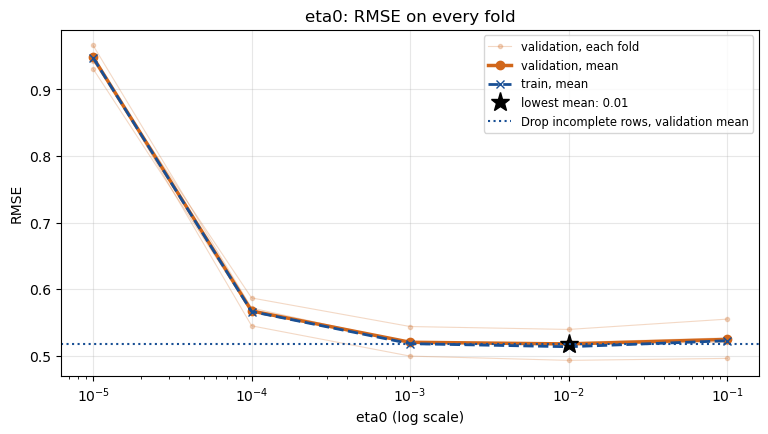

In [10]:
names = {eta0: f'eta0={eta0}' for eta0 in ETA0S}
for eta0, name in names.items():
	sgd(name=name, settings={**SGD_SETTINGS, 'eta0': eta0})
baseline = names[SGD_SETTINGS['eta0']]  # scikit-learn's default, 0.01

display(table(names=[CLOSED_FORM, *names.values()], baseline=baseline))
PLOTTING.parameter_search(
	runs={eta0: RUNS[name] for eta0, name in names.items()},
	parameter='eta0',
	log_x=True,
	reference=(CLOSED_FORM, RUNS[CLOSED_FORM]),
	ymax=YMAX,
	title='eta0: RMSE on every fold',
);
SGD_SETTINGS = {**SGD_SETTINGS, 'eta0': SETTINGS[carried(baseline=baseline, names=names.values())]['eta0']}

### Notes / Observations

- **The default 0.01 is kept:** it has the lowest mean, and the closest other value, 0.001, is 0.49% higher.
- **Too small a step stops before it has learned:** at 0.00001 SGD ends near Dummy (0.9478), even after the most epochs (92).
- **0.1 lands above 0.01 too (+1.31%), on the training rows as well:** a larger step settles less close to the best fit.

## Learning Rate Schedule

Each schedule at the carried `eta0`:
- `constant`: the step stays `eta0`.
- `optimal`: sets its own step from `alpha` and ignores `eta0`.
- `invscaling`: the step is `eta0 / t ** power_t`.
- `adaptive`: keeps `eta0` and divides it by 5 each time the training loss stalls for 5 epochs.

`invscaling`, the default, is the baseline (rule in Method).

In [11]:
names = {schedule: f'learning_rate={schedule}' for schedule in LEARNING_RATE_SCHEDULES}
for schedule, name in names.items():
	sgd(name=name, settings={**SGD_SETTINGS, 'learning_rate': schedule})
baseline = names[SGD_SETTINGS['learning_rate']]  # scikit-learn's default, invscaling

display(table(names=[CLOSED_FORM, *names.values()], baseline=baseline))
SGD_SETTINGS = {**SGD_SETTINGS, 'learning_rate': SETTINGS[carried(baseline=baseline, names=names.values())]['learning_rate']}
display(pd.Series(SGD_SETTINGS, name='carried').astype(str).to_frame())

,validation rmse,train rmse,most epochs,% vs baseline
Drop incomplete rows,0.5178,0.5132,<NA>,+0.02%
learning_rate=constant,0.5239,0.5203,12,+1.21%
learning_rate=optimal,248358515556.2872,244862697211.1572,78,> +999%
learning_rate=invscaling,0.5177,0.5135,7,baseline
learning_rate=adaptive,0.5179,0.5132,43,+0.04%


,carried
penalty,None
learning_rate,invscaling
eta0,0.01
power_t,0.25
max_iter,10000
tol,0.001
random_state,42


### Notes / Observations

- **`invscaling`, the default, is kept:** `adaptive` trains 6 times longer (43 epochs against 7) and still lands 0.04% higher.
- **A step that never shrinks does worse:** `constant` is 1.21% higher, and `optimal`, which sets its own step and ignores `eta0`, diverges.

# Regularization

The carried SGD with a penalty: Ridge (`l2`), Lasso (`l1`) and Elastic Net (`elasticnet`, with `l1_ratio` fixed at 0.5, an even mix of both). `alpha`, the penalty's strength, is tried at 3 values a hundred times apart. Each is compared with the same SGD without a penalty.

,validation rmse,train rmse,most epochs
No penalty,0.5177,0.5135,7
"Ridge, alpha=0.001",0.5177,0.5135,7
"Ridge, alpha=0.1",0.5186,0.5152,7
"Ridge, alpha=10",0.9193,0.9182,9
"Lasso, alpha=0.001",0.5177,0.5135,7
"Lasso, alpha=0.1",0.5438,0.5410,9
"Lasso, alpha=10",1.1280,1.1279,6
"Elastic Net, alpha=0.001",0.5177,0.5135,7
"Elastic Net, alpha=0.1",0.5292,0.5261,8
"Elastic Net, alpha=10",1.1280,1.1279,6


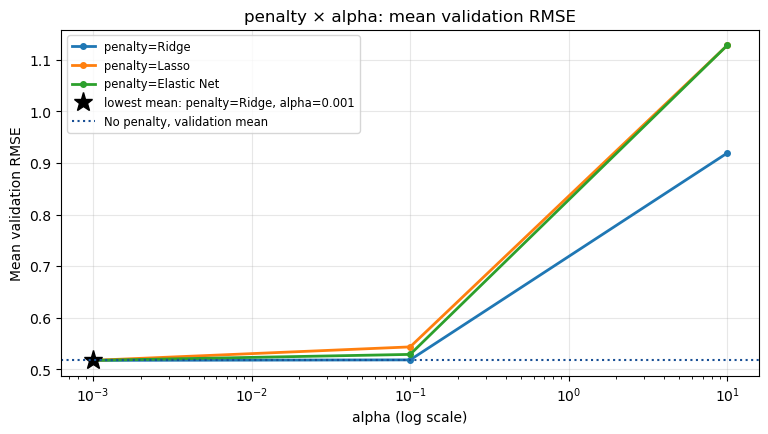

In [12]:
PENALTIES = {'Ridge': 'l2', 'Lasso': 'l1', 'Elastic Net': 'elasticnet'}
sgd(name='No penalty', settings=SGD_SETTINGS)

REGULARIZED = {(label, alpha): f'{label}, alpha={alpha}' for label in PENALTIES for alpha in ALPHAS}
for (label, alpha), name in REGULARIZED.items():
	sgd(name=name, settings={**SGD_SETTINGS, 'penalty': PENALTIES[label], 'alpha': alpha, **({'l1_ratio': L1_RATIO} if label == 'Elastic Net' else {})})

display(table(names=['No penalty', *REGULARIZED.values()]))
PLOTTING.parameter_cross(
	runs={pair: RUNS[name] for pair, name in REGULARIZED.items()},
	lines='penalty',
	x='alpha',
	log_x=True,
	reference=('No penalty', RUNS['No penalty']),
	ymax=YMAX,
);

### Notes / Observations

- **A weak penalty changes nothing:** at alpha 0.001 all three penalties score 0.5177, the same as no penalty.
- **L1 bites first:** at alpha 0.1 Lasso rises to 0.5438 while Ridge barely moves (0.5186); Elastic Net, half L1, lands between them.
- **A strong penalty underfits:** at alpha 10 Ridge's training and validation RMSE rise together (0.9182 and 0.9193), and Lasso and Elastic Net push every coefficient to 0, which predicts the mean (1.1280).

## Why the Target Is Standardized

Every pipeline in this notebook standardizes `Life Ladder` before the model sees it: it subtracts the mean of the training rows and divides by their standard deviation, and the predictions are converted back to `Life Ladder` points before they are scored. Every RMSE in this notebook is in `Life Ladder` points.

This is a change of units, not of shape: the target's distribution looks exactly the same, only the numbers on its axis change. So it has nothing to do with skew or outliers, and it fixes neither. What a change of units does to each model:
- **Closed form and Dummy:** nothing. Least squares gives the same predictions in any units.
- **SGD without a penalty, and Ridge:** almost nothing. Each SGD step is proportional to the error, and so are the coefficients it is heading for, so SGD takes the same path in any units. Only `tol` differs: it is a fixed number compared with the training loss, and the loss grows with the square of the units, so a fit can stop (or `adaptive` can cut its step) a few epochs earlier or later.
- **Lasso and Elastic Net:** what `alpha` means. The L1 penalty pulls every coefficient toward 0 by the same amount on every step, whatever the target's units. So the larger the target's standard deviation, the larger the coefficients and the less the same `alpha` touches them; on a standardized target the standard deviation is 1.

So the target is standardized to put `alpha` and `tol` on the same scale in Q1 and Q2, which share the lists in `consts.py`. The table refits four of this notebook's models without it.

In [13]:
# build(...).regressor is the same pipeline without the target scaler: the model fits and predicts the target in its own units
CHECKS = {  # label: (the run with the target standardized, its model)
	'Closed form': (CLOSED_FORM, PIPELINES.SVDRegression()),
	'SGD, no penalty': ('No penalty', SGDRegressor(**SETTINGS['No penalty'])),
	'Ridge, alpha=0.1': ('Ridge, alpha=0.1', SGDRegressor(**SETTINGS['Ridge, alpha=0.1'])),
	'Lasso, alpha=0.1': ('Lasso, alpha=0.1', SGDRegressor(**SETTINGS['Lasso, alpha=0.1'])),
}
for label, (_, model) in CHECKS.items():
	score(name=f'{label}, target not standardized', pipeline=build(model=model, imputer=IMPUTER).regressor, folds=CV_FOLDS)

display(pd.Series({'mean': y.mean(), 'standard deviation': y.std()}, name=f'{Q1_CONSTS.TARGET}, training rows').to_frame())
pd.DataFrame({
	'target standardized': [RUNS[name]['validation rmse'].mean() for name, _ in CHECKS.values()],
	'target not standardized': [RUNS[f'{label}, target not standardized']['validation rmse'].mean() for label in CHECKS],
}, index=pd.Index(list(CHECKS), name='mean validation rmse'))

,"Life Ladder, training rows"
mean,5.4693
standard deviation,1.1133


,target standardized,target not standardized
mean validation rmse,,
Closed form,0.5178,0.5178
"SGD, no penalty",0.5177,0.5179
"Ridge, alpha=0.1",0.5186,0.5189
"Lasso, alpha=0.1",0.5438,0.5421


### Notes / Observations

- **In Q1 the standardization barely matters:** `Life Ladder`'s standard deviation is 1.1133, close to 1, so its standardized units are almost its own units, and no model moves by more than 0.002.
- **The closed form is identical both ways (0.5178),** and SGD and Ridge move by at most 0.0003, the small difference `tol` can make.
- **Lasso moves the most (0.5438 standardized against 0.5421 not):** it is the only model whose penalty depends on the target's units.

# Selected Model

The homework asks for one regularized model, so the 9 regularized runs are ranked by mean validation RMSE and the lowest is selected.

When no penalty improves on the model without one, the smallest `alpha` tends to win, because it changes the model the least. The selected model is then close to the model without a penalty: it is picked because the homework requires a regularized one, not because the penalty helps.

In [14]:
SELECTED = lowest(names=REGULARIZED.values())
display(pd.Series(SETTINGS[SELECTED], name=SELECTED).astype(str).to_frame())

table(names=['No penalty', SELECTED])

,"Ridge, alpha=0.001"
penalty,l2
learning_rate,invscaling
eta0,0.01
power_t,0.25
max_iter,10000
tol,0.001
random_state,42
alpha,0.001


,validation rmse,train rmse,most epochs
No penalty,0.5177,0.5135,7
"Ridge, alpha=0.001",0.5177,0.5135,7


### Notes / Observations

- **Ridge at alpha 0.001 is picked as required, but in practice it is no penalty:** it ties no penalty to 4 decimals (0.5177), the smallest alpha, as explained above.

## Train on the Entire Training Set

The selected model refit once, with no folds, on every training row kept (the 1,374 complete rows when dropping the incomplete rows is kept, all 1,559 rows when an imputer is carried) and saved. The saved pipeline takes the 8 raw attributes and builds its own columns. When dropping is kept, the saved pipeline has no imputer, so it can only predict complete rows.

In [15]:
X_kept, y_kept = (X.iloc[complete], y.iloc[complete]) if IMPUTER is None else (X, y)  # dropping won: the complete rows only
final = build(model=SGDRegressor(**SETTINGS[SELECTED]), imputer=IMPUTER).fit(X_kept, y_kept)
Q1_CONSTS.MODEL_OUTPUT_DIR.mkdir(exist_ok=True)
joblib.dump(final, Q1_CONSTS.MODEL_OUTPUT_DIR / 'linear_regression.joblib')

pd.Series({
	'training rows': len(X_kept),
	'epochs run': PIPELINES.final_model(pipeline=final).n_iter_,
	'train rmse': mean_squared_error(y_kept, final.predict(X_kept), squared=False),
}, dtype=object).to_frame(SELECTED)  # object: keeps the counts whole numbers

,"Ridge, alpha=0.001"
training rows,1374
epochs run,7
train rmse,0.5139


### Notes / Observations

- **The full fit matches the folds:** on the 1,374 complete rows its training RMSE is 0.5139, against 0.5135 averaged over the folds, and it stops after 7 epochs as they did.

## Training and Validation Loss by Epoch

**What the chart is for:** following training and validation RMSE epoch by epoch, to see when training settles and whether more epochs start to overfit (validation RMSE turning up while training RMSE keeps falling). Each chart shows the selected model on every fold, for as many epochs as it ran on its longest fold.

**Two ways to draw it:**
- **The homework's loop:** a copy of the selected model with `max_iter=1` and `warm_start=True`, fit once per epoch on each fold's training rows, recording training and validation RMSE after each `fit` call.
- **The exact curve:** epoch k is a fresh fit of the selected model with `max_iter=k` and the same seed, which is exactly the first k epochs of its real training. A fold's line goes flat once `tol` stops it.

**Why they differ:** `warm_start=True` carries only the coefficients from one `fit` call to the next. Everything else starts over:

| | One long fit (how the selected model trained) | The homework's loop (one `fit` call per epoch) |
|---|---|---|
| Coefficients | carry on | carry on (`warm_start=True`) |
| Step under `constant` | `eta0` | `eta0`, the same |
| Step under `invscaling` (`eta0 / t ** power_t`, `t` counts the rows seen) | keeps shrinking | starts again at `eta0` every epoch: `fit` sets `t` back to 1 |
| Step under `adaptive` (divided by 5 after 5 epochs without improvement) | shrinks after each stall | stays at `eta0`: a 1-epoch fit can never stall 5 times |
| Order the rows are visited in | a new shuffle every epoch | the same shuffle every epoch: each `fit` starts from the seed |

So the loop replays the real training only under `constant`, and even then it visits the rows in one fixed order. Under the other schedules it trains a different model: one whose step never gets smaller than where a single epoch leaves it. The exact curve shows how the selected model trained; the loop is drawn because the homework asks for it.

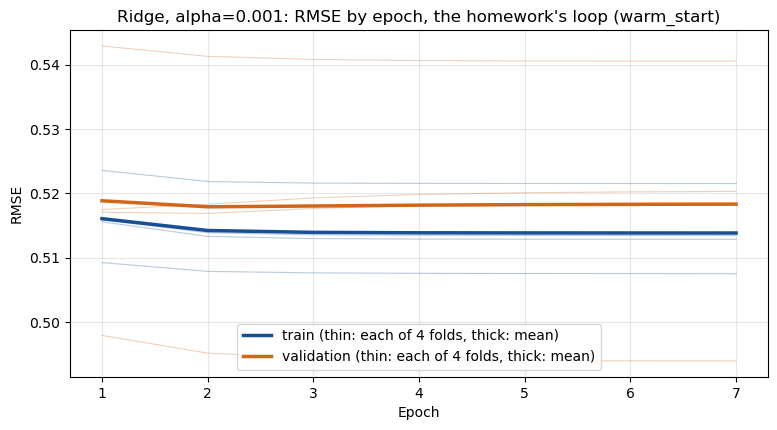

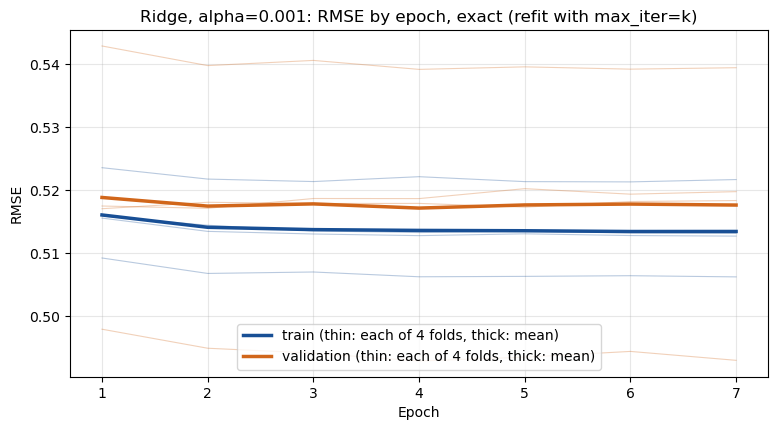

In [16]:
EPOCHS = int(RUNS[SELECTED]['epochs'].max())  # as many epochs as the selected model ran on its longest fold
pipeline = build(model=SGDRegressor(**SETTINGS[SELECTED]), imputer=IMPUTER)
CURVES = {
	method: PIPELINES.epoch_rmse(pipeline=pipeline, X=X, y=y, folds=CV_FOLDS, epochs=EPOCHS, method=method)
	for method in ('warm_start', 'refit')
}
for method, label in (('warm_start', "the homework's loop (warm_start)"), ('refit', 'exact (refit with max_iter=k)')):
	PLOTTING.loss_curve(curve=CURVES[method], title=f'{SELECTED}: RMSE by epoch, {label}', ymax=YMAX);

### Notes / Observations

- **Training is done after 2 epochs:** on the exact curve both lines drop from epoch 1 to 2 and then hold until `tol` stops every fold by epoch 7.
- **More epochs do not overfit:** validation RMSE stays level with training RMSE to the end and never turns up.
- **The folds differ more than the epochs do:** the thin lines spread from about 0.49 to 0.54, while the mean moves by less than 0.002 after epoch 2.

### The Two Curves Side by Side

The mean of the folds for both curves on one chart, and the scores each ends on. The exact curve's last epoch is each fold's full fit, so it ends on the selected model's cross validation score from the Selected Model table; the homework's loop does not.

,validation rmse,train rmse
cross validation (Selected Model),0.5177,0.5135
"homework's loop, last epoch",0.5183,0.5139
"exact curve, last epoch",0.5177,0.5135


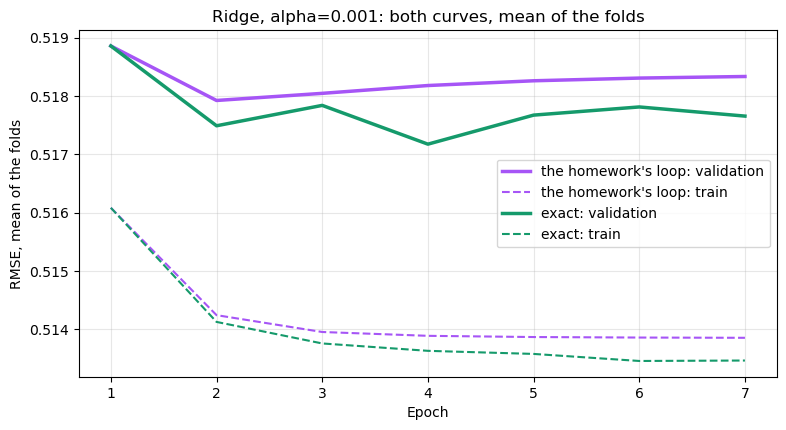

In [17]:
PLOTTING.loss_curve_comparison(curves=CURVES, title=f'{SELECTED}: both curves, mean of the folds', ymax=YMAX);
pd.DataFrame({
	'cross validation (Selected Model)': RUNS[SELECTED][['validation rmse', 'train rmse']].mean(),
	"homework's loop, last epoch": CURVES['warm_start'].xs(EPOCHS, level='epoch').mean(),
	'exact curve, last epoch': CURVES['refit'].xs(EPOCHS, level='epoch').mean(),
}).T[['validation rmse', 'train rmse']]

### Notes / Observations

- **The two curves start together and part at epoch 2:** epoch 1 is the same single pass in both. From epoch 2 the loop restarts `invscaling`'s step at 0.01, while the long fit's step keeps shrinking.
- **Here the difference is small:** the loop ends at 0.5183 against 0.5177. The chart spans less than 0.006, which makes the gap look larger than it is.
- **Only the exact curve ends on the cross validation score (0.5177),** so it is the one that shows how the selected model trained. The loop shows a model whose step restarts at 0.01 every epoch, which ends a little worse.